<div style="background:#0F6E7A;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 1</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Data & Machine Learning Foundations</div>
<div style="font-size:15px;margin-top:6px">Hours 1–5 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

**What you will do today**

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 1 | TEACH | Scientific Python & EDA | UCI Adult Income |
| 2 | TEACH | ML pipelines, cross-validation, gradient boosting | California Housing |
| 3 | BUILD | Churn project: problem framing & baseline | IBM Telco Customer Churn |
| 4 | BUILD | Imbalance, Optuna tuning, SHAP explanations | IBM Telco Customer Churn |
| 5 | BUILD | MLflow tracking, repo, stakeholder summary | Telco + MLflow runs |

> Run every cell top to bottom. All numbers you see below were produced by running this notebook.

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 1 — Scientific Python & Exploratory Data Analysis

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">UCI Adult Income (48,842 rows)</span>
**Skills:** <span style="color:#6A3D9A">NumPy, Pandas, Matplotlib, data cleaning, EDA reasoning</span>

### 1.1 NumPy: why vectorisation matters
A Python loop touches one number at a time. NumPy runs the same operation over a whole array in compiled code.

In [2]:
x = np.random.rand(1_000_000)

t0 = time.perf_counter(); s_loop = sum(v * v for v in x); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s_vec = np.dot(x, x);            t_vec = time.perf_counter() - t0

print(f"Python loop : {t_loop*1000:8.1f} ms")
print(f"NumPy dot   : {t_vec*1000:8.1f} ms   -> {t_loop/t_vec:,.0f}x faster, same answer: {np.isclose(s_loop, s_vec)}")

Python loop :    135.2 ms
NumPy dot   :      0.9 ms   -> 154x faster, same answer: True


### 1.2 Load the Adult Income census data

In [3]:
cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation",
        "relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
adult = pd.read_csv(fetch("https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv", "adult-all.csv"),
                    header=None, names=cols, na_values="?", skipinitialspace=True)
print(adult.shape)
adult.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 1.3 Data quality: types, missing values, duplicates

In [4]:
quality = pd.DataFrame({"dtype": adult.dtypes.astype(str),
                        "missing": adult.isna().sum(),
                        "missing_%": (adult.isna().mean()*100).round(2),
                        "unique": adult.nunique()})
print("Duplicate rows:", adult.duplicated().sum())
quality[quality.missing > 0]

Duplicate rows: 52


,dtype,missing,missing_%,unique
workclass,str,2799,5.73,8
occupation,str,2809,5.75,14
native_country,str,857,1.75,41


In [5]:
# Cleaning decisions (write these down in your README!)
adult_clean = adult.drop_duplicates().copy()
for c in ["workclass", "occupation", "native_country"]:
    adult_clean[c] = adult_clean[c].fillna("Unknown")      # keep rows, make 'missing' an explicit category
adult_clean["high_income"] = (adult_clean.income == ">50K").astype(int)
print(adult_clean.shape, "| positive rate:", round(adult_clean.high_income.mean(), 3))

(48790, 16) | positive rate: 0.239


### 1.4 Visual EDA: who earns more than 50K?

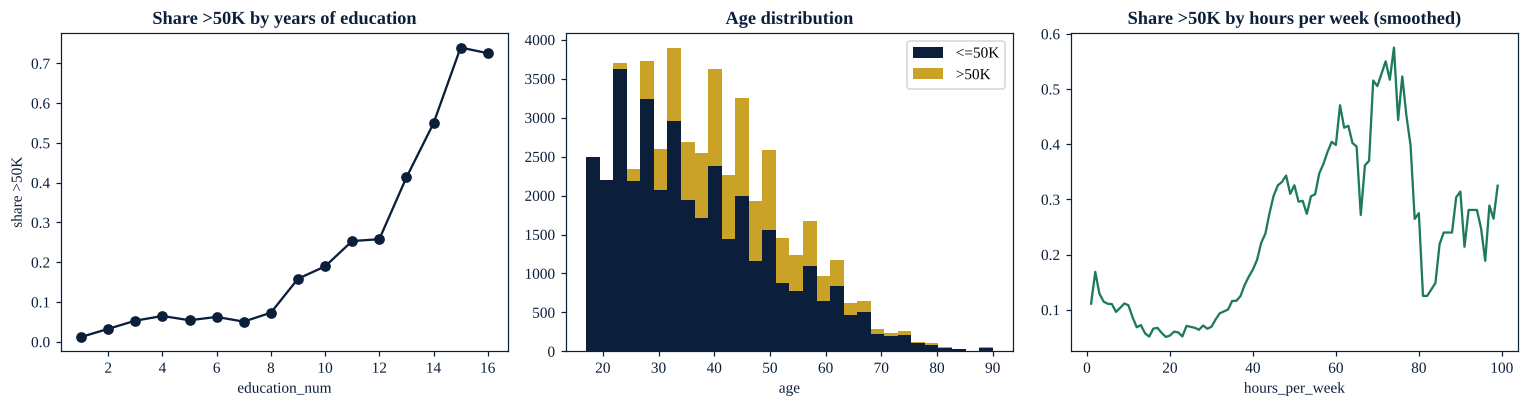

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
adult_clean.groupby("education_num").high_income.mean().plot(ax=ax[0], marker="o", color=NAVY)
ax[0].set(title="Share >50K by years of education", xlabel="education_num", ylabel="share >50K")
ax[1].hist([adult_clean.age[adult_clean.high_income==0], adult_clean.age[adult_clean.high_income==1]],
           bins=30, stacked=True, color=[NAVY, GOLD], label=["<=50K", ">50K"])
ax[1].set(title="Age distribution", xlabel="age"); ax[1].legend()
adult_clean.groupby("hours_per_week").high_income.mean().rolling(5, min_periods=1).mean().plot(ax=ax[2], color=GREEN)
ax[2].set(title="Share >50K by hours per week (smoothed)", xlabel="hours_per_week")
plt.tight_layout(); plt.savefig(FIG/"s1_adult_eda.png", bbox_inches="tight"); plt.show()

In [7]:
# Group comparisons are where EDA turns into questions (and later into fairness checks on Sunday 6)
adult_clean.groupby("sex").high_income.agg(["mean", "count"]).round(3)

,mean,count
sex,,
Female,0.109,16176
Male,0.304,32614


**EDA reasoning — write 3 findings in your own words.** Example: *income share rises steadily with years of education*;
*the >50K group is older on average*; *there is a large gap between groups by sex, which is a fairness question, not just a feature.*

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 2 — Supervised ML pipeline, cross-validation, gradient boosting

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">California Housing (20,640 districts)</span>
**Skills:** <span style="color:#6A3D9A">scikit-learn Pipelines, k-fold CV, XGBoost, feature engineering</span>

In [8]:
housing = pd.read_csv(fetch("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv", "housing.csv"))
print(housing.shape); housing.head(3)

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


In [9]:
# Feature engineering: ratios are often more informative than raw totals
h = housing.copy()
h["rooms_per_household"] = h.total_rooms / h.households
h["bedrooms_per_room"]   = h.total_bedrooms / h.total_rooms
h["population_per_household"] = h.population / h.households
y = h.pop("median_house_value"); X = h

from sklearn.model_selection import train_test_split, KFold, cross_val_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

train: (16512, 12)  test: (4128, 12)


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

num_cols = X.select_dtypes("number").columns.tolist(); cat_cols = ["ocean_proximity"]
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

models = {"Linear regression": LinearRegression(),
          "Random forest": RandomForestRegressor(n_estimators=120, n_jobs=-1, random_state=SEED),
          "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.8, n_jobs=2, random_state=SEED)}
cv = KFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1)
    rows.append({"model": name, "CV RMSE mean": rmse.mean().round(0), "CV RMSE std": rmse.std().round(0)})
cv_table = pd.DataFrame(rows).sort_values("CV RMSE mean"); cv_table

,model,CV RMSE mean,CV RMSE std
2,XGBoost,45339.0,967.0
1,Random forest,50258.0,1038.0
0,Linear regression,67859.0,1312.0


Test RMSE: $44,355   |   Test R^2: 0.850


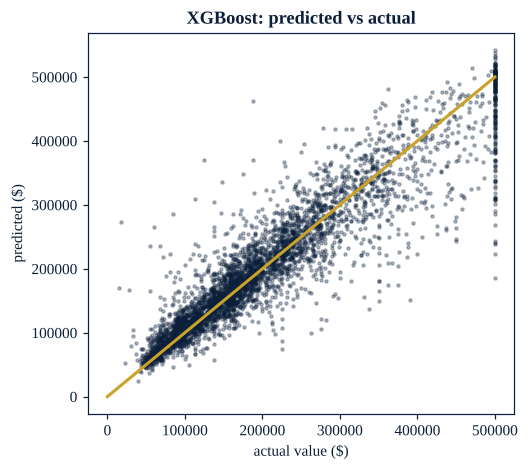

In [11]:
# Fit the best model on all training data, evaluate ONCE on the untouched test set
from sklearn.metrics import root_mean_squared_error, r2_score
best = Pipeline([("prep", prep), ("model", models["XGBoost"])]).fit(X_train, y_train)
pred = best.predict(X_test)
print(f"Test RMSE: ${root_mean_squared_error(y_test, pred):,.0f}   |   Test R^2: {r2_score(y_test, pred):.3f}")

plt.figure(figsize=(5, 4.5))
plt.scatter(y_test, pred, s=4, alpha=0.3, color=NAVY); plt.plot([0, 5e5], [0, 5e5], color=GOLD, lw=2)
plt.title("XGBoost: predicted vs actual"); plt.xlabel("actual value ($)"); plt.ylabel("predicted ($)")
plt.savefig(FIG/"s1_housing_pred.png", bbox_inches="tight"); plt.show()

> **Note the cap at \$500,001.** The dataset truncates expensive districts — a data-collection artefact. Spotting things
> like this is part of being an AI scientist, not just a model trainer.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 3 — Churn project kick-off: problem framing and baseline

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">IBM Telco Customer Churn (7,043 customers)</span>
**Skills:** <span style="color:#6A3D9A">Problem framing, baseline thinking, F1 / ROC-AUC</span>

**Business question:** *Which customers are likely to cancel next month, so the retention team can call them first?*

* **Unit of prediction:** one customer · **Target:** `Churn = Yes`
* **Success metric:** ROC-AUC (ranking quality) and F1 for the churn class (calls are expensive, misses are expensive)

In [12]:
telco = pd.read_csv(fetch("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv", "telco_churn.csv"))
telco["TotalCharges"] = pd.to_numeric(telco.TotalCharges, errors="coerce")   # 11 blank strings -> NaN (new customers)
print(telco.shape, "| blank TotalCharges:", telco.TotalCharges.isna().sum())
telco["churn"] = (telco.Churn == "Yes").astype(int)
print("Churn rate:", round(telco.churn.mean(), 3))
telco.groupby("Contract").churn.mean().round(3)

(7043, 21) | blank TotalCharges: 11
Churn rate: 0.265


Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: churn, dtype: float64

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, classification_report

Xc = telco.drop(columns=["customerID", "Churn", "churn"]); yc = telco.churn
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=SEED)
c_num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]; c_cat = [c for c in Xc.columns if c not in c_num]
c_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), c_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), c_cat)])

def evaluate(name, model):
    pipe = Pipeline([("prep", c_prep), ("model", model)]).fit(Xc_tr, yc_tr)
    proba = pipe.predict_proba(Xc_te)[:, 1]
    return pipe, {"model": name, "ROC-AUC": round(roc_auc_score(yc_te, proba), 3),
                  "F1 (churn)": round(f1_score(yc_te, (proba >= 0.5).astype(int)), 3)}

results = []
_, r = evaluate("Majority-class dummy", DummyClassifier(strategy="most_frequent")); results.append(r)
logit, r = evaluate("Logistic regression", LogisticRegression(max_iter=2000)); results.append(r)
pd.DataFrame(results)

,model,ROC-AUC,F1 (churn)
0,Majority-class dummy,0.500,0.000
1,Logistic regression,0.846,0.607


The dummy gets 73% accuracy by never predicting churn — and an F1 of 0. **Accuracy hides failure on imbalanced data.**

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 4 — Improve the model: imbalance, Optuna tuning, SHAP

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">IBM Telco Customer Churn</span>
**Skills:** <span style="color:#6A3D9A">Optuna, class weighting, SHAP explainability</span>

In [14]:
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from sklearn.model_selection import StratifiedKFold

pos_weight = (yc_tr == 0).sum() / (yc_tr == 1).sum()       # class weighting instead of oversampling
print("scale_pos_weight =", round(pos_weight, 2))

def objective(trial):
    params = dict(n_estimators=trial.suggest_int("n_estimators", 100, 500),
                  max_depth=trial.suggest_int("max_depth", 2, 6),
                  learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  subsample=trial.suggest_float("subsample", 0.6, 1.0),
                  colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                  min_child_weight=trial.suggest_int("min_child_weight", 1, 10))
    pipe = Pipeline([("prep", c_prep), ("model", XGBClassifier(**params, scale_pos_weight=pos_weight, n_jobs=2,
                                                               random_state=SEED, eval_metric="logloss"))])
    return cross_val_score(pipe, Xc_tr, yc_tr, cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=25)
print("Best CV ROC-AUC:", round(study.best_value, 4)); study.best_params

scale_pos_weight = 2.77


Best CV ROC-AUC: 0.8473


{'n_estimators': 172,
 'max_depth': 2,
 'learning_rate': 0.03931705714389733,
 'subsample': 0.6924821636216919,
 'colsample_bytree': 0.5974790200860086,
 'min_child_weight': 3}

In [15]:
xgb_pipe, r = evaluate("XGBoost + class weight + Optuna",
                       XGBClassifier(**study.best_params, scale_pos_weight=pos_weight, n_jobs=2, random_state=SEED, eval_metric="logloss"))
results.append(r)
_, r = evaluate("Logistic regression + class weight", LogisticRegression(max_iter=2000, class_weight="balanced")); results.append(r)
leaderboard = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False); leaderboard

,model,ROC-AUC,F1 (churn)
2,XGBoost + class weight + Optuna,0.847,0.632
1,Logistic regression,0.846,0.607
3,Logistic regression + class weight,0.846,0.627
0,Majority-class dummy,0.500,0.000


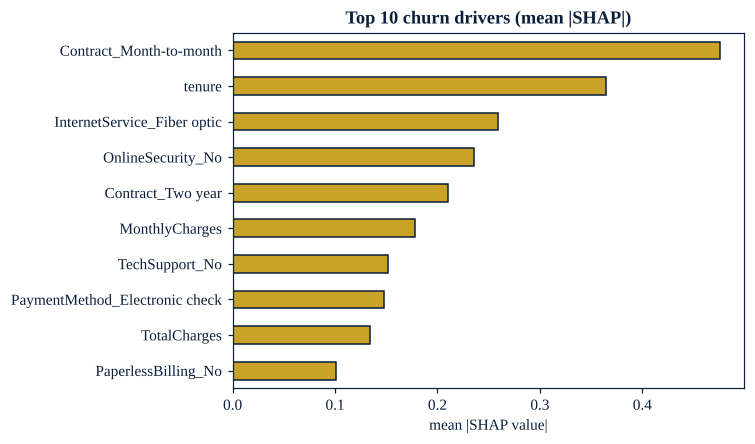

Contract_Month-to-month        0.476
tenure                         0.365
InternetService_Fiber optic    0.259
OnlineSecurity_No              0.236
Contract_Two year              0.210
dtype: float32

In [16]:
import shap
Xt = xgb_pipe.named_steps["prep"].transform(Xc_te)
feat_names = xgb_pipe.named_steps["prep"].get_feature_names_out()
explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
sv = explainer.shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(0), index=[f.split("__")[1] for f in feat_names]).sort_values(ascending=False)

plt.figure(figsize=(6, 4.2))
imp.head(10)[::-1].plot.barh(color=GOLD, edgecolor=NAVY)
plt.title("Top 10 churn drivers (mean |SHAP|)"); plt.xlabel("mean |SHAP value|")
plt.savefig(FIG/"s1_shap.png", bbox_inches="tight"); plt.show()
imp.head(5).round(3)

**Translate SHAP for the business:** month-to-month contracts, short tenure and fibre-optic internet push churn risk up.
That suggests concrete actions — e.g. a loyalty offer before month 12 for month-to-month customers.
SHAP shows *association in the model*, not proof of cause.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 5 — Track experiments, publish the repo, present

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Telco + MLflow runs</span>
**Skills:** <span style="color:#6A3D9A">MLflow, Git/GitHub workflow, technical storytelling</span>

In [17]:
import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("P1-churn-intelligence")
for row in results:
    with mlflow.start_run(run_name=row["model"]):
        mlflow.log_param("model", row["model"])
        mlflow.log_metrics({"roc_auc": row["ROC-AUC"], "f1_churn": row["F1 (churn)"]})
runs = mlflow.search_runs()[["tags.mlflow.runName", "metrics.roc_auc", "metrics.f1_churn"]]
runs.sort_values("metrics.roc_auc", ascending=False)

2026/11/25 12:55:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 12:55:28 INFO mlflow.store.db.utils: Updating database tables


2026/11/25 12:55:30 INFO mlflow.tracking.fluent: Experiment with name 'P1-churn-intelligence' does not exist. Creating a new experiment.


,tags.mlflow.runName,metrics.roc_auc,metrics.f1_churn
1,XGBoost + class weight + Optuna,0.847,0.632
0,Logistic regression + class weight,0.846,0.627
2,Logistic regression,0.846,0.607
3,Majority-class dummy,0.500,0.000


Open the MLflow UI locally with `mlflow ui --backend-store-uri sqlite:///mlflow.db` to compare runs visually.

In [18]:
# One-page business summary, generated from the actual results
best = leaderboard.iloc[0]
summary = f"""# Churn Intelligence — one-page summary
**Question:** which customers will cancel next month?
**Data:** IBM Telco Customer Churn, {len(telco):,} customers, churn rate {telco.churn.mean():.1%}.
**Best model:** {best['model']} — ROC-AUC {best['ROC-AUC']}, F1 (churn) {best['F1 (churn)']} on a held-out 25% test set.
**Top drivers:** {', '.join(imp.head(3).index)}.
**Recommendation:** target month-to-month customers in their first year with a retention offer.
**Limits:** one company, one snapshot in time; SHAP shows model associations, not causes.
"""
print(summary)

# Churn Intelligence — one-page summary
**Question:** which customers will cancel next month?
**Data:** IBM Telco Customer Churn, 7,043 customers, churn rate 26.5%.
**Best model:** XGBoost + class weight + Optuna — ROC-AUC 0.847, F1 (churn) 0.632 on a held-out 25% test set.
**Top drivers:** Contract_Month-to-month, tenure, InternetService_Fiber optic.
**Recommendation:** target month-to-month customers in their first year with a retention offer.
**Limits:** one company, one snapshot in time; SHAP shows model associations, not causes.



---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P1-churn-intelligence/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P1-churn-intelligence/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-1 -m "Sunday 1 submission"</code> → <code>git push origin sunday-1</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>